# Fitting $k_p$ for CMB lensing validation of CoLoRe

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on
- The notebook just uses the CMB lensing convergence $\kappa$ values of the boxes and validates it through the auto-spectrum.
- The kappa values can be found in `./data/...test_box/`, along with $C_{\ell}$ (and its associated errors), and a logarithmic rebinning run with `./scripts/rebin_cls_kk.py`, which is the one used in this notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import camb

from scipy.integrate import quad
from scipy.constants import c
from scipy.optimize import minimize_scalar
import sys
sys.path.append('../')

from py.rebinning import log_bin_cls  
import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
})

# Theory CMB lensing auto-spectrum $C_{\ell}^{\kappa \kappa}$

## setting up CAMB

In [2]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [3]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
    window=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build:

    1. CAMBparams instance
    2. CAMB results object

    Parameters
    ----------
    cosmo_dict : dict
        Dictionary containing cosmological parameters

    z_pk : list or None
        Redshifts for P(k) interpolator.
        If None, defaults to [0.0]

    kmax : float
        Maximum k [1/Mpc]

    lmax : integer
        Maximum multipole

    nonlinear : bool
        Whether to use nonlinear P(k)
    """

    # --------------------------------------------------
    # Convert to CAMB inputs
    # --------------------------------------------------

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # --------------------------------------------------
    # Initial CAMB params
    # --------------------------------------------------

    pars = camb.CAMBparams()

    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )

    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # --------------------------------------------------
    # Matter power settings
    # --------------------------------------------------

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    if window:
        # 1. Use a dense grid but restricted range to keep memory light
        z_win = np.linspace(0, 12.0, 400)
        z_cut = cosmo_dict["z_max"]
        
        # 2. Smooth taper (Essential: hard steps often cause Fortran NaN crashes)
        w_z = 0.5 * (1 - np.tanh((z_win - z_cut) / 0.1))
        
        # 3. Use SplinedSourceWindow from sources
        wind = camb.sources.SplinedSourceWindow(source_type='lensing')
        wind.set_table(z=z_win, W=w_z)
        
        # 4. Attach as a list
        pars.SourceWindows = [wind]
        
        # 5. CRITICAL FLAGS FOR STABILITY
        pars.Want_Sources = True
        pars.SourceTerms.limber_windows = True  # Use Limber to avoid complex integrals
        pars.SourceTerms.counts_density = False # Turn off extra terms to save memory
        pars.SourceTerms.counts_redshift = False



    # Final results
    results = camb.get_results(pars)

    return results

## manual Limber integral

In [4]:
def w_kappa(chi, z_chi, chi_source, cosmo_params):
    '''
    CMB lensing convergence kernel
    '''
    
    # scale factor at redshift of lensing structure
    a = 1.0 / (1.0 + z_chi)
    c_kms = c*1E-3

    # cosmological parameters
    H0, om = cosmo_params
    
    # prefactor of the kernel
    w_prefactor = (1.5) * (H0/c_kms)**2 * om * (chi_source - chi)/chi_source
    w_geom = (chi/a)
    
    return w_prefactor * w_geom

In [5]:
def limber(chi, k_p, ell, kmax, chi_source,cosmo_params, pk_interp, results):
    '''
    CMB lensing auto-spectrum using Limber approximation
    '''

    # converting chi to redshift
    z_chi = results.redshift_at_comoving_radial_distance(chi)
    k = (ell + 0.5) / chi  
    kp = k_p  # (1/Mpc) k pressure parameter scale used for smoothing the power spectrum according to the colore simulation resolution


    # kernel and pk interpolator, filtering out of extrapolation k and small k
    if 1e-4 < k < kmax:
        win = w_kappa(chi, z_chi, chi_source, cosmo_params)
        pk = pk_interp.P(z_chi, k, grid=False)
        smooth = np.exp(-(k/kp)**2)  # smoothing factor to avoid oscillations at high k 
        return (win**2 / chi**2) * pk * smooth
        
    else:
        return 0

In [6]:
def get_limber_cls(k_p, cosmo_params_filename, z_pk, kmax=100.0, lmin=2,lmax=2500):
    '''
    Compute the C_l^kk using the Limber approximation for the given k_p and cosmological parameters
    '''

    # get linear and non-linear matter power spectrum
    cosmo_dict = load_cosmology(cosmo_params_filename)
    z_max = cosmo_dict["z_max"]

    results_lin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=False)
    
    # comoving distance of the last scattering surface 
    z_star = results_lin.get_derived_params()['zstar']  # z_star doesn't match z_out until third box
    chi_star = results_lin.comoving_radial_distance(z_star)
    chi_max = results_lin.comoving_radial_distance(z_max)  # comoving distance of z_max

    # Hubble parameter and matter density for the kernel
    H0 = cosmo_dict["h"] * 100
    om = cosmo_dict["omega_M"]
    cosmo_params = (H0, om)

    # get the matter power spectrum interpolators for linear and non-linear cases
    pk_interp_lin = results_lin.get_matter_power_interpolator(nonlinear=False, 
                                                      hubble_units=False, 
                                                      k_hunit=False,  
                                                      var1='delta_tot', 
                                                      var2='delta_tot')
    
    #store the cls from linear and nonlinear limber approximation integration
    # redshift integration up to zmax
    ells = np.arange(lmin, lmax+1)
    cl_kk_lin_zmax_zs = np.zeros(ells.shape)

    # manually integrate the limber approximation
    for i, ell in enumerate(ells):
        
        # integral up to redshift z_max, source plane at z_star
        chi_source = chi_star
        chi_cut = chi_max
        cl_kk_lin_zmax_zs[i] = quad(limber, 0.001, chi_cut, args=(k_p, ell, kmax, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]

    return {
        'ells': ells,
        'cl_kk_lin_zmax_zs': cl_kk_lin_zmax_zs,
    }


# CoLoRe simulation auto-spectrum $C_{\ell}^{\kappa \kappa}$

In [7]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)
    ells_colore, cl_kk_colore, err_tt = data['ells'], data['cls'], data['err']

    return ells_colore, cl_kk_colore, err_tt

## minimizer (fitting just for $L<1000$)

In [8]:
def get_chi2(k_p, cosmo_params_filename, box_filename, z_pk, lmin_fit, lmax_fit,kmax=100.0):
    '''
    Compute the chi-squared statistic for the fit of the theoretical C_l^kk to the Colore data
    '''

    # load the Colore data and rebin it to match the binning of the theoretical C_l^kk
    ells_data, cl_kk_data, err_data = get_colore_cls(box_filename)
    if lmin_fit is None:
        lmin_fit = 2
    if lmax_fit is None:
        lmax_fit = 1000
    nbins = 30
    cl_kk_data, err_data = log_bin_cls(ells_data, cl_kk_data, nbins=nbins, ell_min = lmin_fit, ell_max = lmax_fit)[1:] 

    # compute the theoretical C_l^kk using the Limber approximation for the given k_p and cosmological parameters and rebin it to match the data
    lmin, lmax = 2, 2500
    results = get_limber_cls(k_p, cosmo_params_filename, z_pk, kmax=kmax, lmin=lmin, lmax=lmax)
    ells_theory, cl_kk_theory = results['ells'], results['cl_kk_lin_zmax_zs']
    cl_kk_theory = log_bin_cls(ells_theory, cl_kk_theory, nbins=nbins, ell_min = lmin_fit, ell_max = lmax_fit)[1]

    # filter out any NaN values that may arise from the rebinning process
    mask = np.isfinite(cl_kk_data) & np.isfinite(cl_kk_theory) & np.isfinite(err_data)
    cl_kk_data, err_data, cl_kk_theory = cl_kk_data[mask], err_data[mask], cl_kk_theory[mask]

    # compute the chi-squared statistic, summing over the bins of the data
    chi2 = np.sum(((cl_kk_data - cl_kk_theory) / err_data)**2)
    ndof = len(cl_kk_data) - 1  # number of degrees of freedom, fitting one parameter k_p

    return chi2 / ndof  # reduced chi-squared

In [9]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1]  # reverse to have high redshift first for CAMB

In [10]:
lmin_fit, lmax_fit = 2, 1000
result = minimize_scalar(get_chi2, bounds=(0.1, 0.5), method='bounded', 
                         args=('../data/third_test_box/cosmo_params.json', '../data/third_test_box/cl_kk.npz', z_pk, lmin_fit, lmax_fit))
best_kp = result.x
chi2_best_kp = result.fun

In [11]:
print(f"Best-fit k_p: {best_kp:.3f} 1/Mpc")
print(f"Reduced chi-squared at best-fit k_p: {chi2_best_kp:.3f}")

Best-fit k_p: 0.312 1/Mpc
Reduced chi-squared at best-fit k_p: 1.201


## plots

In [12]:
def plot_chi2(kp_array, chi_array):
    '''
    Plot the chi-squared statistic as a function of k_p for the fit of the theoretical C_l^kk to the Colore data
    '''
    
    plt.figure(figsize=(6, 4), dpi=120)

    plt.plot(kp_array, chi_array, marker='.')
    plt.scatter(best_kp, chi2_best_kp, s=50, c='red', label=rf'$\chi^2_\nu = {chi2_best_kp:.2f}$')

    plt.axvline(
        best_kp,
        color='red',
        ls='--',
        alpha=0.7
    )

    # annotation
    plt.annotate(
        rf'$k_p = {best_kp:.3f}$',
        xy=(best_kp, chi2_best_kp),
        xytext=(10, 25),
        textcoords='offset points',
        color='red'
    )

    plt.xlabel(r'$k_p$ [1/Mpc]')
    plt.ylabel(r'$\chi^2_\nu$')
    plt.title(r'CMB Lensing Auto-Spectrum $\chi^2$-Fit of $k_p$')
    plt.savefig('./plots/kp_fit_chi2.png', dpi=150, bbox_inches='tight')
    plt.savefig('./plots/kp_fit_chi2.pdf', dpi=150, bbox_inches='tight')
    plt.legend()
    plt.show()

In [15]:
kp_array = np.linspace(0.1, 0.5, 20)
chi2_array = [get_chi2(k_p, '../data/third_test_box/cosmo_params.json', '../data/third_test_box/cl_kk.npz', z_pk, lmin_fit, lmax_fit) for k_p in kp_array]

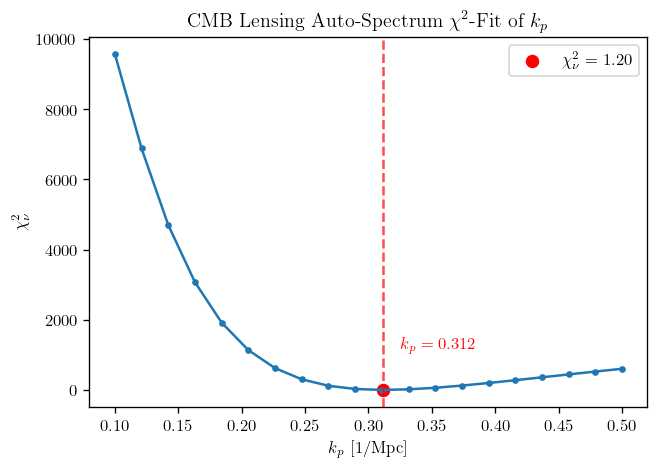

In [16]:
plot_chi2(kp_array, chi2_array)